## Import libraries

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

## Load movie data

In [2]:
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"

movies = pd.read_csv(DATA_DIR / "movies.csv")

movies["genres"] = (
    movies["genres"]
    .fillna("")
    .replace("(no genres listed)", "")
)

print("Total movies:", len(movies))
display(movies.head())

Total movies: 9742


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


## Prepare genre text

In [3]:
movies["genre_text"] = (
    movies["genres"]
    .str.replace("|", " ", regex=False)
    .str.strip()
)

display(movies[["title", "genres", "genre_text"]].head(10))

,title,genres,genre_text
0,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,Adventure Animation Children Comedy Fantasy
1,Jumanji (1995),Adventure|Children|Fantasy,Adventure Children Fantasy
2,Grumpier Old Men (1995),Comedy|Romance,Comedy Romance
3,Waiting to Exhale (1995),Comedy|Drama|Romance,Comedy Drama Romance
4,Father of the Bride Part II (1995),Comedy,Comedy
5,Heat (1995),Action|Crime|Thriller,Action Crime Thriller
6,Sabrina (1995),Comedy|Romance,Comedy Romance
7,Tom and Huck (1995),Adventure|Children,Adventure Children
8,Sudden Death (1995),Action,Action
9,GoldenEye (1995),Action|Adventure|Thriller,Action Adventure Thriller


## Convert genres into numerical features

In [4]:
vectorizer = TfidfVectorizer(
    token_pattern=r"(?u)\b\w+\b",
    lowercase=True
)

movie_vectors = vectorizer.fit_transform(
    movies["genre_text"]
)

print("Number of movies:", movie_vectors.shape[0])
print("Number of genre features:", movie_vectors.shape[1])
print("Feature names:", vectorizer.get_feature_names_out())

Number of movies: 9742
Number of genre features: 21
Feature names: ['action' 'adventure' 'animation' 'children' 'comedy' 'crime'
 'documentary' 'drama' 'fantasy' 'fi' 'film' 'horror' 'imax' 'musical'
 'mystery' 'noir' 'romance' 'sci' 'thriller' 'war' 'western']


## Calculate cosine similarity

In [5]:
similarity_matrix = cosine_similarity(
    movie_vectors,
    dense_output=True
)

print("Similarity matrix shape:", similarity_matrix.shape)

Similarity matrix shape: (9742, 9742)


## Create a title lookup

In [6]:
title_to_index = {
    title: index
    for index, title in enumerate(movies["title"])
}

print("Example movie:", movies.iloc[0]["title"])
print("Its row index:", title_to_index[movies.iloc[0]["title"]])

Example movie: Toy Story (1995)
Its row index: 0


## Build the recommendation function

In [7]:
def recommend_movies(movie_title, top_n=10):
    if movie_title not in title_to_index:
        matches = [
            title for title in title_to_index
            if movie_title.lower() in title.lower()
        ]

        if matches:
            print("Exact title not found. Possible matches:")
            for title in matches[:10]:
                print("-", title)
        else:
            print("Movie title not found in the dataset.")

        return pd.DataFrame(
            columns=["title", "genres", "similarity_score"]
        )

    movie_index = title_to_index[movie_title]

    scores = similarity_matrix[movie_index].copy()

    # Do not recommend the movie itself
    scores[movie_index] = -1

    # Find the most similar movies
    ranked_indices = np.argsort(scores)[::-1][:top_n]

    results = movies.iloc[ranked_indices][
        ["title", "genres"]
    ].copy()

    results["similarity_score"] = scores[ranked_indices]

    return results.reset_index(drop=True)

## Test your first recommendation

In [8]:
movie_to_search = "Toy Story (1995)"

recommendations = recommend_movies(
    movie_to_search,
    top_n=10
)

print("Movies similar to:", movie_to_search)
display(recommendations)

Movies similar to: Toy Story (1995)


,title,genres,similarity_score
0,Shrek the Third (2007),Adventure|Animation|Children|Comedy|Fantasy,1.0
1,"Adventures of Rocky and Bullwinkle, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
2,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
3,Turbo (2013),Adventure|Animation|Children|Comedy|Fantasy,1.0
4,The Good Dinosaur (2015),Adventure|Animation|Children|Comedy|Fantasy,1.0
5,"Tale of Despereaux, The (2008)",Adventure|Animation|Children|Comedy|Fantasy,1.0
6,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,1.0
7,"Wild, The (2006)",Adventure|Animation|Children|Comedy|Fantasy,1.0
8,Moana (2016),Adventure|Animation|Children|Comedy|Fantasy,1.0
9,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,1.0


## Compare recommendations for several movies

In [9]:
test_movies = [
    "Toy Story (1995)",
    "Jumanji (1995)",
    "The Matrix (1999)",
    "Jurassic Park (1993)"
]

for title in test_movies:
    print(f"\nRecommendations for {title}")
    display(recommend_movies(title, top_n=5))


Recommendations for Toy Story (1995)


,title,genres,similarity_score
0,Shrek the Third (2007),Adventure|Animation|Children|Comedy|Fantasy,1.0
1,"Adventures of Rocky and Bullwinkle, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
2,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
3,Turbo (2013),Adventure|Animation|Children|Comedy|Fantasy,1.0
4,The Good Dinosaur (2015),Adventure|Animation|Children|Comedy|Fantasy,1.0



Recommendations for Jumanji (1995)


,title,genres,similarity_score
0,The Cave of the Golden Rose (1991),Adventure|Children|Fantasy,1.0
1,Seventh Son (2014),Adventure|Children|Fantasy,1.0
2,Pete's Dragon (2016),Adventure|Children|Fantasy,1.0
3,Pan (2015),Adventure|Children|Fantasy,1.0
4,"Indian in the Cupboard, The (1995)",Adventure|Children|Fantasy,1.0



Recommendations for The Matrix (1999)
Movie title not found in the dataset.


,title,genres,similarity_score



Recommendations for Jurassic Park (1993)


,title,genres,similarity_score
0,"Lost World: Jurassic Park, The (1997)",Action|Adventure|Sci-Fi|Thriller,1.0
1,Spawn (1997),Action|Adventure|Sci-Fi|Thriller,1.0
2,"I, Robot (2004)",Action|Adventure|Sci-Fi|Thriller,1.0
3,Babylon A.D. (2008),Action|Adventure|Sci-Fi|Thriller,1.0
4,Death Race (2008),Action|Adventure|Sci-Fi|Thriller,1.0


## Visualize similarity scores

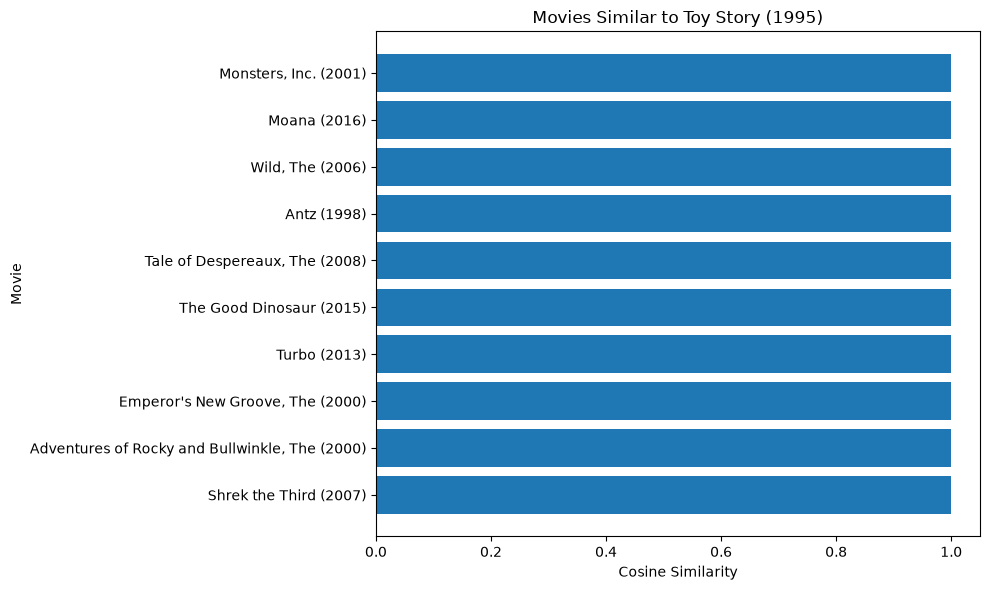

In [10]:
recommendations = recommend_movies(
    "Toy Story (1995)",
    top_n=10
)

if not recommendations.empty:
    plot_data = recommendations.sort_values(
        "similarity_score",
        ascending=True
    )

    plt.figure(figsize=(10, 6))
    plt.barh(
        plot_data["title"],
        plot_data["similarity_score"]
    )

    plt.xlabel("Cosine Similarity")
    plt.ylabel("Movie")
    plt.title("Movies Similar to Toy Story (1995)")
    plt.tight_layout()
    plt.show()

## Test an invalid title

In [11]:
recommend_movies("This Movie Does Not Exist", top_n=5)

Movie title not found in the dataset.


,title,genres,similarity_score


## Content-Based Recommendation Conclusion

- Movie genres were converted into numerical features using TF-IDF.
- Cosine similarity was used to compare movie feature vectors.
- The system can recommend movies similar to a selected movie.
- The model does not yet learn individual user preferences.
- Genre-only similarity has limitations because movies can share genres but differ in story, quality, and audience appeal.
- The next stage is to develop collaborative filtering using user ratings.